# A5-1 신용 점수 회귀와 연체 위험 분류

이 노트북은 `src/`의 모듈을 단계별로 불러 실행 결과를 보여주는 보고서다. 계산 로직은 노트북에 두지 않고 `.py` 파일에 둔다(보너스 2: 모듈화).
같은 결과를 한 번에 만들려면 `uv run python -m src.run_all`을 실행한다.

데이터는 `python data_gen.py`로 만든 **합성 데이터**이며, 결과는 실제 금융 고객에 대한 결론이 아니다.

In [1]:
import warnings
import pandas as pd
from IPython.display import Image, display

from src import baseline, classification, diagnostics, regression, report
from src.config import FIGURES_DIR, FEATURES
from src.data import describe, load_data, split_data

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 4)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = load_data()
info = describe(df)
print(f"{info['rows']:,}행, 결측치 {info['missing_values']}개, 연체 비율 {info['overdue_rate']:.2%}")
print(f"소득 하한 1,500으로 잘린 행: {info['income_floor_rows']}개")
df.head()

10,000행, 결측치 0개, 연체 비율 12.01%
소득 하한 1,500으로 잘린 행: 408개


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,credit_score,is_overdue
0,50,3406.0,54,0.29,1,1,295.0,0
1,25,2161.0,7,0.78,2,0,259.0,1
2,56,6390.0,83,0.88,9,2,323.0,0
3,54,2821.0,10,0.01,2,2,377.0,0
4,50,4925.0,90,0.06,7,1,395.0,0


## 1. 데이터 관찰

- `credit_score`는 소득·연체 횟수·부채 비율의 **선형 결합 + 표준편차 30 노이즈**로 만들어진다.
- `is_overdue`는 점수 하위 15%(292점 미만) 중 **무작위 80%만** 1이다. 나머지 20%는 같은 조건이어도 0이다.
- `age`, `spending_score`, `credit_card_count`는 어떤 타깃에도 쓰이지 않은 노이즈 변수다.

,credit_score,is_overdue
age,-0.0180,-0.0040
annual_income,0.7283,-0.3815
spending_score,0.0019,0.0025
debt_ratio,-0.3696,0.2183
credit_card_count,0.0136,0.0019
overdue_count_6m,-0.4467,0.3281


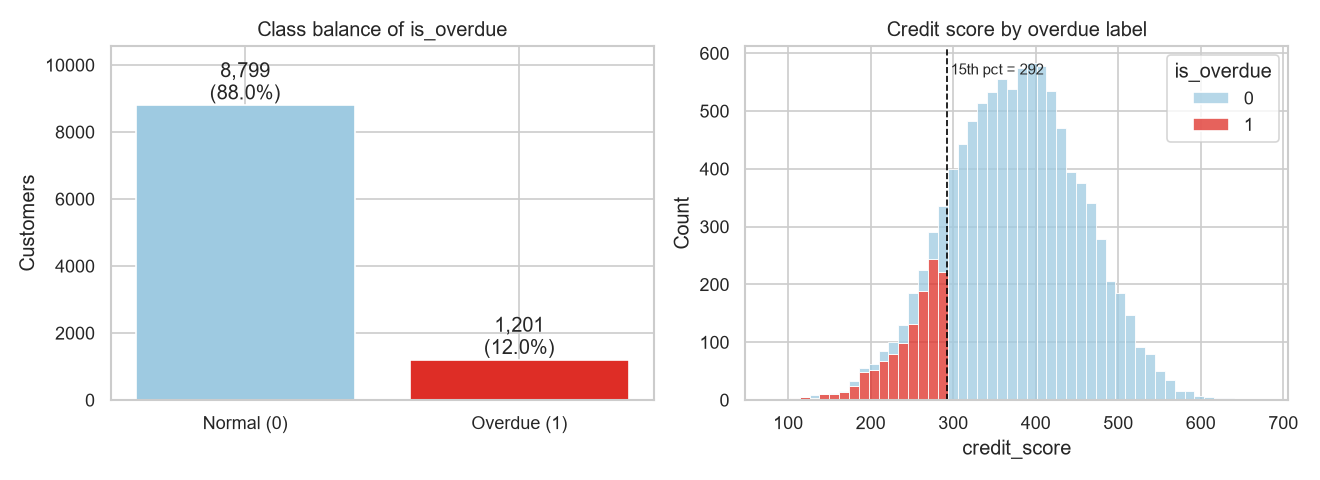

In [2]:
corr = pd.DataFrame(info["correlation_with_targets"]).loc[FEATURES]
display(corr)
report.data_overview(df, FIGURES_DIR / "01_data_overview.png")
display(Image(FIGURES_DIR / "01_data_overview.png"))

## 2. 분할

8:2 층화 분할(`random_state=42`). 이후 모든 `fit`은 Train에서만 일어나고 Test는 마지막 평가에만 쓴다.

In [3]:
split = split_data(df)
pd.DataFrame({
    "rows": [len(split.X_train), len(split.X_test)],
    "overdue_rate": [split.y_clf_train.mean(), split.y_clf_test.mean()],
}, index=["train", "test"])

,rows,overdue_rate
train,8000,0.1201
test,2000,0.1200


## 3. 규칙 기반 베이스라인

학습 없이 심사 직관으로 정한 규칙 6개. 하나라도 걸리면 연체로 예측한다. 걸린 규칙 수를 위험 점수로 써서 AUC를 계산한다.

In [4]:
hits = baseline.rule_hits(split.X_test)
rule_table = pd.DataFrame({
    "rule": [r["label"] for r in baseline.RULES],
    "flagged_share": hits.mean().to_numpy(),
    "overdue_rate_when_flagged": [split.y_clf_test[hits[r["id"]]].mean() for r in baseline.RULES],
}, index=hits.columns)
display(rule_table)
rb = baseline.RuleBasedClassifier()
pd.Series(classification.classification_metrics(
    split.y_clf_test, rb.predict(split.X_test), rb.predict_proba(split.X_test)[:, 1]))

,rule,flagged_share,overdue_rate_when_flagged
R1,최근 6개월 연체 2회 이상,0.0940,0.3989
R2,부채 비율 80% 초과,0.2055,0.2433
R3,"연 소득 3,000만원 미만",0.1500,0.4100
R4,연체 이력이 있고 부채 비율 60% 초과,0.1675,0.3075
R5,"연 소득 4,000만원 미만이고 부채 비율 50% 초과",0.1620,0.4228
R6,신용카드 8장 이상 보유,0.2280,0.1272


accuracy                                          0.513
precision                                        0.1947
recall                                            0.975
f1                                               0.3245
roc_auc                                          0.8589
pr_auc                                           0.4585
confusion    {'tn': 792, 'fp': 968, 'fn': 6, 'tp': 234}
dtype: object

## 4. 전처리 파이프라인

`DerivedFeatures`(보너스 1)로 연령대·부채액을 만들고, 수치형은 중앙값 대치 → 표준화, 범주형은 최빈값 대치 → 원-핫 인코딩한다.
아래 평균값이 Train 평균과 일치하면, 스케일러가 Train에서만 학습됐다는 뜻이다.

In [5]:
from src.features import build_preprocessor
prep = build_preprocessor().fit(split.X_train)
print(list(prep.get_feature_names_out()))
scaler = prep.named_steps["columns"].named_transformers_["num"].named_steps["scale"]
pd.DataFrame({"scaler_mean": scaler.mean_[:6], "train_mean": split.X_train.mean().to_numpy(),
              "test_mean": split.X_test.mean().to_numpy()}, index=FEATURES)

['age', 'annual_income', 'spending_score', 'debt_ratio', 'credit_card_count', 'overdue_count_6m', 'debt_amount', 'age_group_20-29', 'age_group_30-39', 'age_group_40-49', 'age_group_50-59', 'age_group_60-69']


,scaler_mean,train_mean,test_mean
age,44.7638,44.7638,44.0470
annual_income,5036.5544,5036.5544,5021.6890
spending_score,49.7524,49.7524,50.3615
debt_ratio,0.5009,0.5009,0.5028
credit_card_count,5.0163,5.0163,5.0255
overdue_count_6m,0.5061,0.5061,0.5055


## 5. 회귀: Ridge와 Lasso

Alpha 0.01, 0.1, 1, 10, 100에서 계수 변화를 본다. 계수는 표준화된 변수 1 표준편차당 점수 변화다.

Ridge                              Lasso                \
                  0.01   0.10   1.00   10.00  100.00 0.01   0.10   1.00     
age                 0.32   0.32   0.31   0.24  -0.01  -0.05  -0.09  -0.00   
annual_income      57.03  57.03  57.02  56.93  56.07  57.10  57.68  57.02   
spending_score     -0.16  -0.16  -0.16  -0.16  -0.15  -0.15  -0.06  -0.00   
debt_ratio        -30.24 -30.24 -30.24 -30.25 -30.25 -30.12 -29.03 -27.78   
credit_card_count   0.18   0.18   0.18   0.18   0.19   0.17   0.08   0.00   
overdue_count_6m  -35.88 -35.87 -35.87 -35.83 -35.43 -35.87 -35.78 -34.87   
debt_amount         1.84   1.84   1.85   1.91   2.34   1.70   0.45  -0.00   
age_group_20-29     0.33   0.33   0.32   0.22  -0.10  -0.00  -0.00  -0.00   
age_group_30-39     0.68   0.68   0.67   0.62   0.44   0.55   0.00   0.00   
age_group_40-49     0.83   0.83   0.83   0.83   0.77   0.96   0.33   0.00   
age_group_50-59    -1.11  -1.11  -1.11  -1.05  -0.83  -0.63  -0.33  -0.00   
age_group_60-69    -0.73  -0.73  -0.72  -0.62  -0.29  -0.00  -0.00  -0.00   

                                 
                  10.00  100.00  
age                -0.00    0.0  
annual_income      48.04    0.0  
spending_score      0.00    0.0  
debt_ratio        -18.81    0.0  
credit_card_count   0.00    0.0  
overdue_count_6m  -25.79    0.0  
debt_amount        -0.00    0.0  
age_group_20-29     0.00    0.0  
age_group_30-39     0.00    0.0  
age_group_40-49     0.00    0.0  
age_group_50-59    -0.00    0.0  
age_group_60-69    -0.00    0.0

Ridge 0.01 → 0이 된 변수: 없음
Ridge 0.1 → 0이 된 변수: 없음
Ridge 1 → 0이 된 변수: 없음
Ridge 10 → 0이 된 변수: 없음
Ridge 100 → 0이 된 변수: 없음
Lasso 0.01 → 0이 된 변수: ['age_group_20-29', 'age_group_60-69']
Lasso 0.1 → 0이 된 변수: ['age_group_20-29', 'age_group_30-39', 'age_group_60-69']
Lasso 1 → 0이 된 변수: ['age', 'spending_score', 'credit_card_count', 'debt_amount', 'age_group_20-29', 'age_group_30-39', 'age_group_40-49', 'age_group_50-59', 'age_group_60-69']
Lasso 10 → 0이 된 변수: ['age', 'spending_score', 'credit_card_count', 'debt_amount', 'age_group_20-29', 'age_group_30-39', 'age_group_40-49', 'age_group_50-59', 'age_group_60-69']
Lasso 100 → 0이 된 변수: ['age', 'annual_income', 'spending_score', 'debt_ratio', 'credit_card_count', 'overdue_count_6m', 'debt_amount', 'age_group_20-29', 'age_group_30-39', 'age_group_40-49', 'age_group_50-59', 'age_group_60-69']


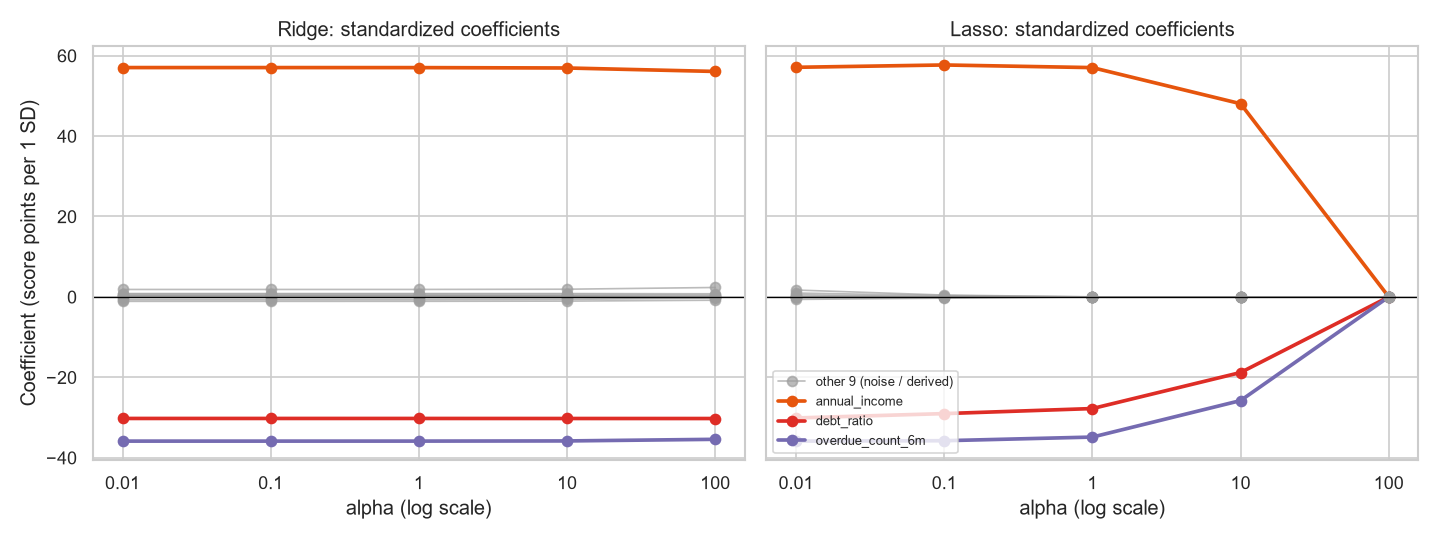

In [6]:
paths = regression.coefficient_paths(split)
coef = pd.DataFrame({(m, r["alpha"]): r["coefficients"] for m, rows in paths.items() for r in rows}).round(2)
display(coef)
for m, rows in paths.items():
    for r in rows:
        print(m, r["alpha"], "→ 0이 된 변수:", r["zero_coefficients"] or "없음")
report.coefficient_paths(paths, FIGURES_DIR / "02_coefficient_paths.png")
display(Image(FIGURES_DIR / "02_coefficient_paths.png"))

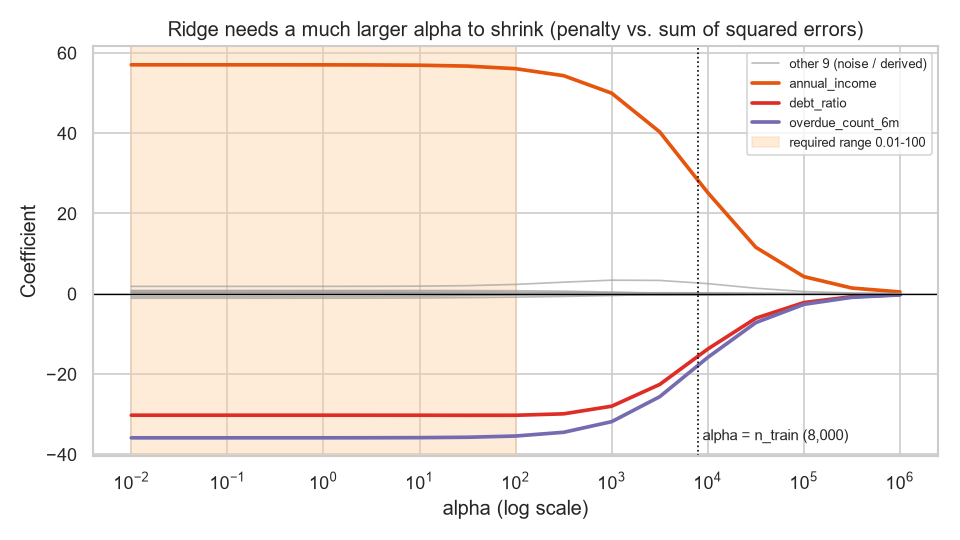

,alpha,rmse,mae,r2
Mean baseline,NaN,80.8737,64.7302,-0.0004
LinearRegression,NaN,30.1309,23.9377,0.8611
Ridge,10.0,30.1343,23.9404,0.8611
Lasso,0.1,30.1288,23.9317,0.8612


In [7]:
extended = regression.extended_ridge_path(split)
report.ridge_extended(extended, FIGURES_DIR / "03_ridge_extended_alpha.png")
display(Image(FIGURES_DIR / "03_ridge_extended_alpha.png"))
reg = regression.tune_and_compare(split)
pd.DataFrame({k: {"alpha": v["alpha"], **v["test"]} for k, v in reg["results"].items()}).T

같은 Alpha라도 scikit-learn의 Ridge는 오차 제곱의 **합**, Lasso는 **평균의 1/2**에 규제를 더한다.
Train이 8,000건이므로 Ridge는 Alpha가 수천 이상이 되어야 눈에 띄게 줄어든다. RMSE 약 30은 생성 노이즈 표준편차 30과 같아서, 선형 모델이 줄일 수 있는 오차를 거의 다 줄였다는 뜻이다.

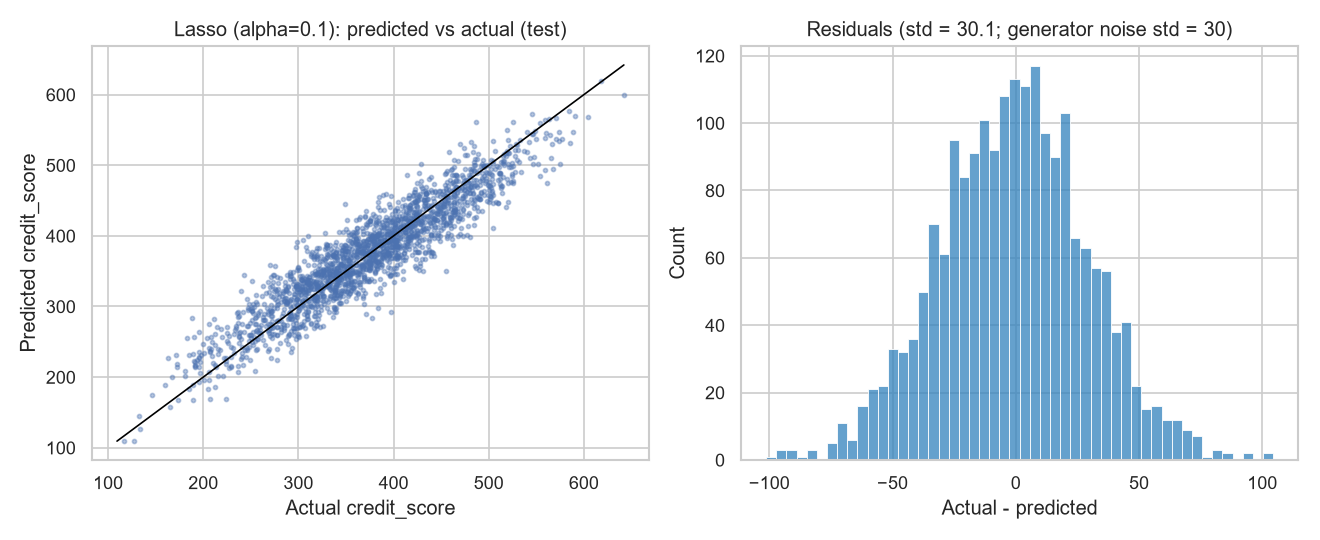

In [8]:
report.regression_fit(split.y_reg_test, reg["predictions"]["Lasso"],
                      f"Lasso (alpha={reg['results']['Lasso']['alpha']})", FIGURES_DIR / "04_regression_fit.png")
display(Image(FIGURES_DIR / "04_regression_fit.png"))

## 6. 분류: 불균형 처리와 앙상블

로지스틱 회귀에 처리 없음 / `class_weight='balanced'` / SMOTE를 비교하고, Random Forest(class_weight, SMOTE)와 XGBoost(scale_pos_weight)를 GridSearchCV로 튜닝한다.
수 분이 걸린다.

In [9]:
models = classification.fit_models(split)
table = pd.DataFrame({
    k: {"cv_f1": None if v["cv"] is None else v["cv"]["f1_mean"],
        "cv_f1_std": None if v["cv"] is None else v["cv"]["f1_std"],
        **{m: v["test"][m] for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]}}
    for k, v in models.items()}).T
display(table)
for k, v in models.items():
    if v.get("best_params"):
        print(k, v["best_params"])

,cv_f1,cv_f1_std,accuracy,precision,recall,f1,roc_auc,pr_auc
Rule baseline,NaN,NaN,0.5130,0.1947,0.9750,0.3245,0.8589,0.4585
LogReg (no handling),0.6123,0.0506,0.9175,0.6923,0.5625,0.6207,0.9498,0.6849
LogReg + class_weight,0.6448,0.0214,0.8770,0.4930,0.8750,0.6306,0.9495,0.6834
LogReg + SMOTE,0.6552,0.0234,0.8820,0.5049,0.8583,0.6358,0.9494,0.6831
RF + class_weight,0.6599,0.0177,0.8960,0.5457,0.7958,0.6475,0.9399,0.6336
RF + SMOTE,0.6645,0.0177,0.9015,0.5642,0.7875,0.6574,0.9383,0.6024
XGB + scale_pos_weight,0.6562,0.0181,0.8830,0.5076,0.8333,0.6309,0.9446,0.6709


RF + class_weight {'max_depth': 12, 'min_samples_leaf': 1, 'n_estimators': 400}
RF + SMOTE {'max_depth': 16, 'min_samples_leaf': 1, 'n_estimators': 400}
XGB + scale_pos_weight {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 200}


In [10]:
selection = classification.select_final(models)
final = selection["final"]
print(selection)
oracle = classification.oracle_ceiling(df.loc[split.X_test.index, "credit_score"].to_numpy(),
                                       split.y_clf_test, df["credit_score"].quantile(0.15))
print("생성 규칙을 아는 경우의 상한:", {k: round(v, 3) for k, v in oracle.items() if k != "confusion"})

{'best_cv': 'RF + SMOTE', 'cutoff': 0.6566054866288098, 'within_one_std': ['RF + class_weight', 'RF + SMOTE'], 'final': 'RF + class_weight'}
생성 규칙을 아는 경우의 상한: {'accuracy': 0.97, 'precision': 0.8, 'recall': 1.0, 'f1': 0.889, 'roc_auc': 0.983, 'pr_auc': 0.81}


비교 모델: LogReg + class_weight / 불순도 중요도 모델: RF + class_weight


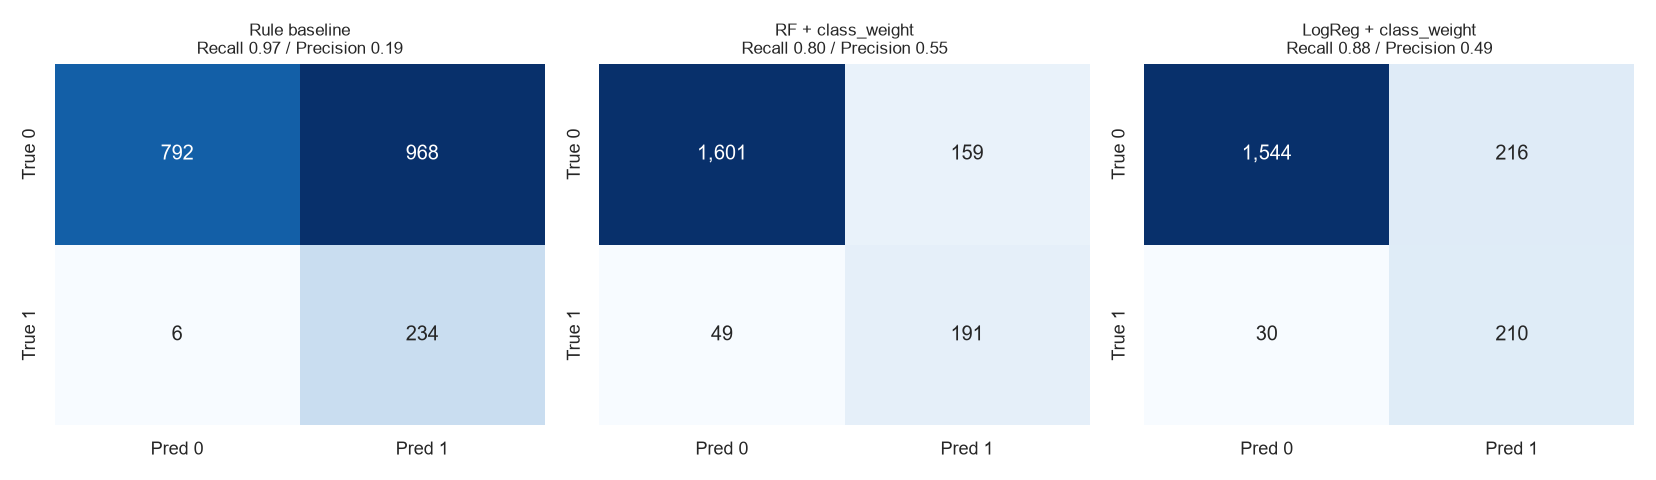

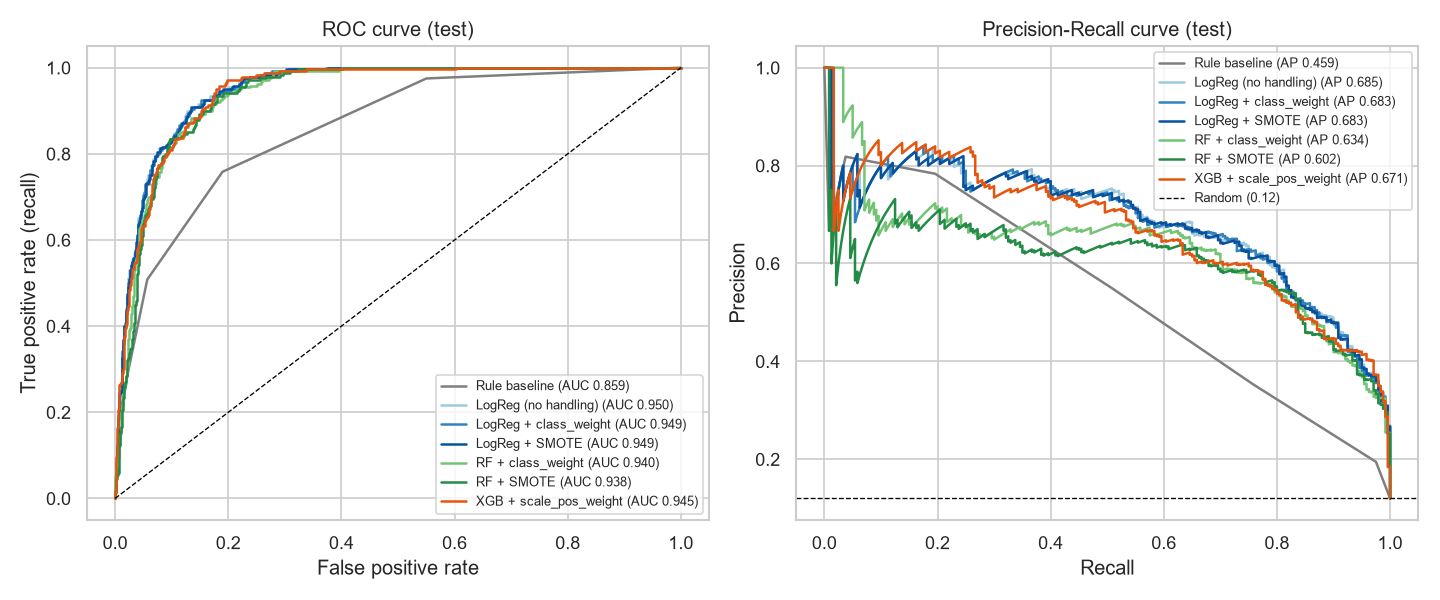

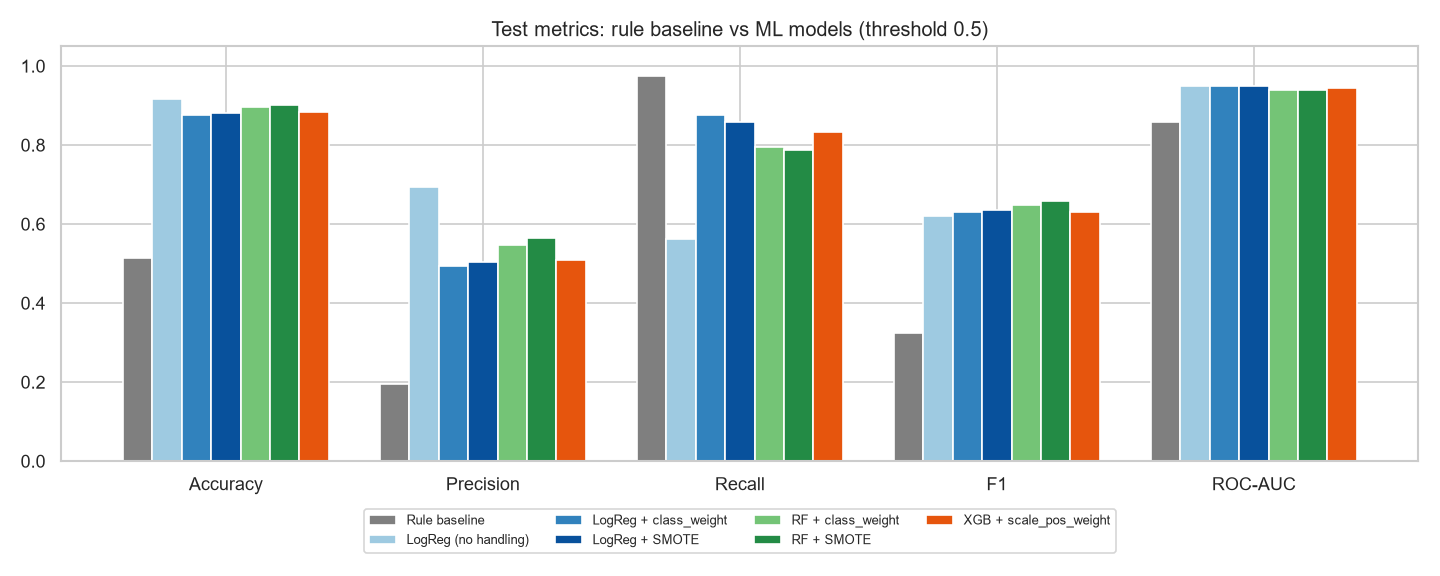

In [11]:
compare = classification.comparison_models(models, final)
contrast = compare["contrast"]
print("비교 모델:", contrast, "/ 불순도 중요도 모델:", compare["tree"])
report.confusion_matrices(models, ["Rule baseline", final, contrast], FIGURES_DIR / "05_confusion_matrices.png")
report.roc_pr_curves(models, split.y_clf_test, FIGURES_DIR / "06_roc_pr_curves.png")
report.model_comparison(models, FIGURES_DIR / "07_model_comparison.png")
for name in ["05_confusion_matrices", "06_roc_pr_curves", "07_model_comparison"]:
    display(Image(FIGURES_DIR / f"{name}.png"))

## 7. 특징 중요도

불순도 중요도는 학습 데이터 기준이고 원-핫 변수를 따로 센다. Permutation 중요도는 Test에서 원본 변수 하나를 섞었을 때 PR-AUC가 떨어지는 정도다.

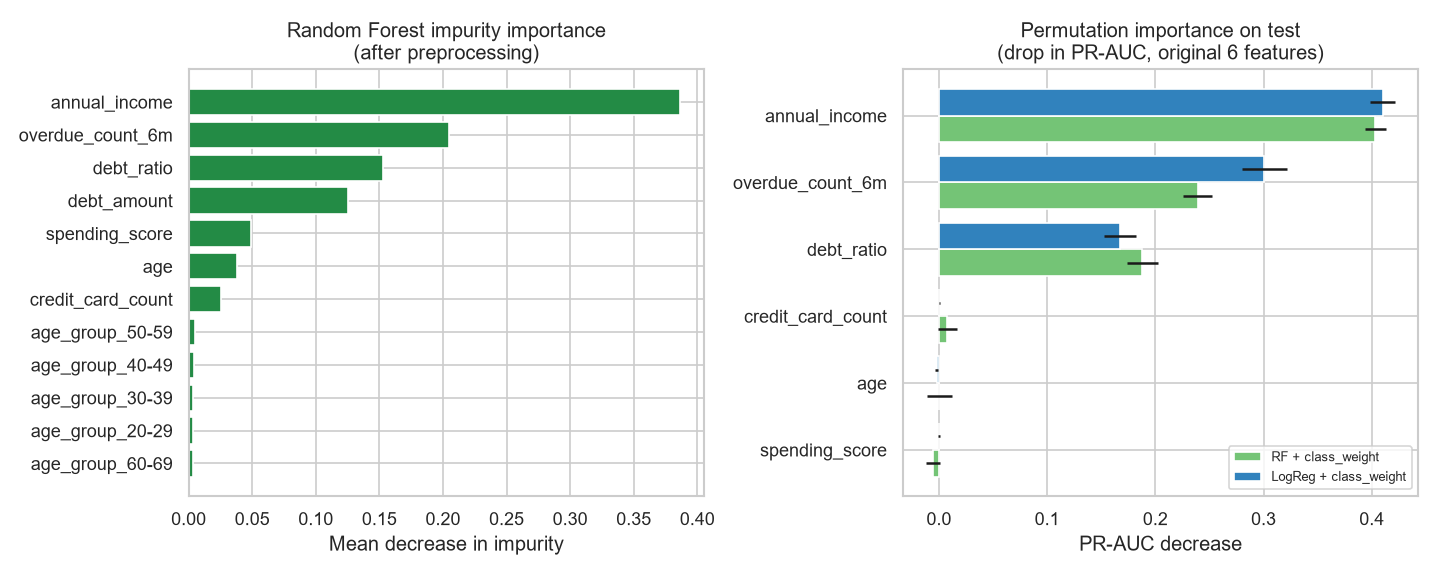

,RF + class_weight,LogReg + class_weight
annual_income,0.4034,4.0995e-01
overdue_count_6m,0.2392,3.0077e-01
debt_ratio,0.1877,1.6730e-01
credit_card_count,0.0077,2.5747e-04
age,0.0003,-2.0555e-03
spending_score,-0.0055,-2.6768e-05


In [12]:
permutation = {k: diagnostics.permutation_on_test(models[k]["estimator"], split.X_test, split.y_clf_test)
               for k in (final, contrast)}
tree_imp = diagnostics.tree_importance(models[compare["tree"]]["estimator"])
report.feature_importance(tree_imp, permutation, FIGURES_DIR / "08_feature_importance.png")
display(Image(FIGURES_DIR / "08_feature_importance.png"))
pd.DataFrame({k: {f: v["mean"] for f, v in p.items()} for k, p in permutation.items()})

## 8. 학습 곡선 (보너스 3)

Train과 Validation 곡선의 간격은 분산(과대적합), 두 곡선이 함께 머무는 높이는 편향을 보여준다.

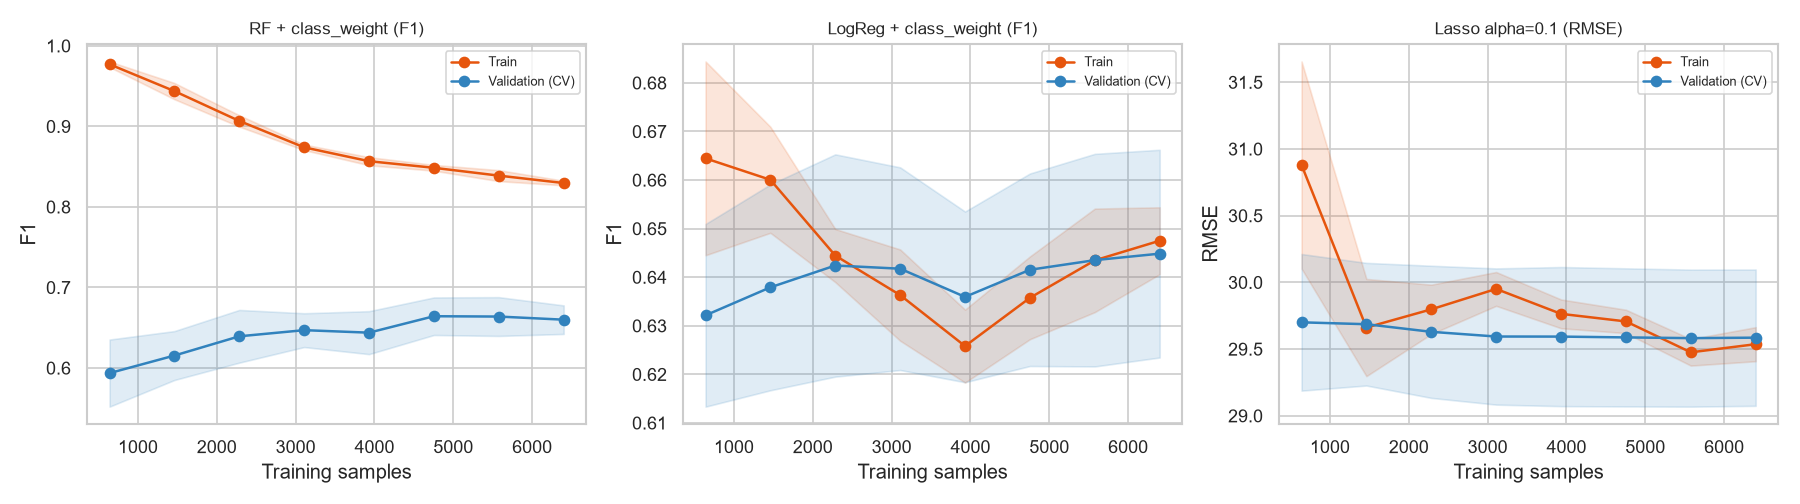

{'RF + class_weight (F1)': 0.1697,
 'LogReg + class_weight (F1)': 0.0027,
 'Lasso alpha=0.1 (RMSE)': -0.049}

In [13]:
from sklearn.linear_model import Lasso
lasso_alpha = reg["results"]["Lasso"]["alpha"]
curves = {
    f"{final} (F1)": diagnostics.classification_learning_curve(models[final]["estimator"], split.X_train, split.y_clf_train),
    f"{contrast} (F1)": diagnostics.classification_learning_curve(models[contrast]["estimator"], split.X_train, split.y_clf_train),
    f"Lasso alpha={lasso_alpha} (RMSE)": diagnostics.regression_learning_curve(
        regression.make_pipeline(Lasso(alpha=lasso_alpha, max_iter=50_000)), split.X_train, split.y_reg_train),
}
report.learning_curves(curves, FIGURES_DIR / "09_learning_curves.png")
display(Image(FIGURES_DIR / "09_learning_curves.png"))
{k: round(c["final_gap"], 4) for k, c in curves.items()}

## 9. 승인·보류·거절 정책

임계값은 Test가 아니라 Train의 교차 검증 예측(out-of-fold)으로 정한다. 보류 임계값은 연체자의 95%를 보류 이상으로 보내는 가장 높은 값, 거절 임계값은 F1이 가장 높은 값이다.

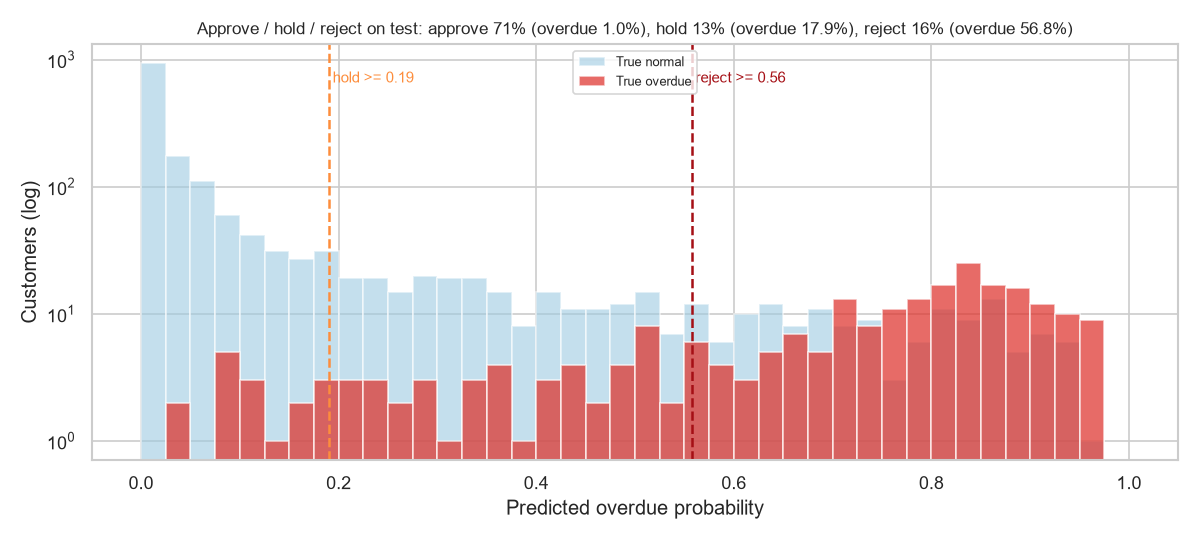

보류 ≥ 0.190, 거절 ≥ 0.557


,customers,share,overdue,overdue_rate
approve,1422.0,0.7110,14.0,0.0098
hold,263.0,0.1315,47.0,0.1787
reject,315.0,0.1575,179.0,0.5683


In [14]:
policy = classification.decision_policy(models[final]["estimator"], split)
report.decision_policy(models[final]["proba"], split.y_clf_test, policy, FIGURES_DIR / "10_decision_policy.png")
display(Image(FIGURES_DIR / "10_decision_policy.png"))
print(f"보류 ≥ {policy['hold_threshold']:.3f}, 거절 ≥ {policy['reject_threshold']:.3f}")
pd.DataFrame(policy["test_bands"]).T

## 정리

결과 수치와 해석은 `README.md`와 `results/report.md`에, 개념 설명과 직접 조작 실험은 `study/a5-1.html`에 있다.